# 3단계 검수: Train/Validation 분할과 중복 그룹 확인

이 Notebook은 모델 성능을 평가하는 Notebook이 아닙니다. 다음 두 가지를 확인합니다.

1. Train/Validation ID 분할에 누락이나 겹침이 없는지 자동 검사
2. `duplicate_component_id`로 묶인 샘플이 실제로 유사해 보이는지 이미지로 검수

현재 그룹 기준은 **두 Train 샘플이 단색이 아닌 동일 이미지 byte를 3장 이상 공유하는 경우**입니다. Test 데이터는 읽지 않습니다.

In [1]:
from ast import literal_eval
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import display

# 프로젝트 루트와 notebooks/ 중 어디에서 실행해도 경로를 찾습니다.
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'train.csv').exists():
    ROOT = ROOT.parent

assert (ROOT / 'data' / 'train.csv').exists(), '프로젝트 루트를 찾지 못했습니다.'
print(f'프로젝트 루트: {ROOT}')

Matplotlib is building the font cache; this may take a moment.


프로젝트 루트: /Users/hyejin/SNU


## 1. 분할 파일 불러오기

원본 `train.csv`, 3단계에서 만든 분할 ID, 2단계에서 만든 이미지 해시 결과를 읽습니다. 원본 파일은 수정하지 않습니다.

In [2]:
train_csv = pd.read_csv(ROOT / 'data' / 'train.csv', encoding='utf-8-sig')
train_split = pd.read_csv(ROOT / 'outputs' / 'splits' / 'train_ids.csv')
validation_split = pd.read_csv(ROOT / 'outputs' / 'splits' / 'validation_ids.csv')
image_metrics = pd.read_csv(ROOT / 'outputs' / 'eda' / 'image_metrics.csv')
split_df = pd.concat([train_split, validation_split], ignore_index=True)

print(f'원본 Train 샘플: {len(train_csv):,}')
print(f'분할 Train 샘플: {len(train_split):,}')
print(f'분할 Validation 샘플: {len(validation_split):,}')
print(f'이미지 메타데이터: {len(image_metrics):,}')

원본 Train 샘플: 9,535
분할 Train 샘플: 7,628
분할 Validation 샘플: 1,907
이미지 메타데이터: 38,140


## 2. 자동 무결성 검사

아래 셀이 모두 통과하면 최소한 다음 조건은 만족합니다.

- Train과 Validation ID가 겹치지 않음
- 두 집합을 합치면 원본 Train 전체가 됨
- 모든 sample ID에 이미지가 정확히 4장 존재함
- 하나의 중복 그룹이 두 split으로 갈라지지 않음

In [3]:
original_ids = set(train_csv['Id'])
train_ids = set(train_split['Id'])
validation_ids = set(validation_split['Id'])

assert train_ids.isdisjoint(validation_ids), 'Train과 Validation에 겹치는 ID가 있습니다.'
assert train_ids | validation_ids == original_ids, '누락되거나 추가된 ID가 있습니다.'
assert not split_df['Id'].duplicated().any(), '분할 파일 안에 중복 ID가 있습니다.'
assert set(split_df['split']) == {'train', 'validation'}

group_split_counts = split_df.groupby('duplicate_component_id')['split'].nunique()
assert group_split_counts.max() == 1, '한 중복 그룹이 Train과 Validation 양쪽으로 갈라졌습니다.'

missing_or_extra_images = []
for sample_id in original_ids:
    image_count = len(list((ROOT / 'data' / 'train' / sample_id).glob('*.jpg')))
    if image_count != 4:
        missing_or_extra_images.append((sample_id, image_count))
assert not missing_or_extra_images, missing_or_extra_images[:10]

print('✓ Train/Validation ID 겹침 없음')
print('✓ 전체 9,535개 Train ID를 빠짐없이 포함')
print('✓ 모든 sample ID에 JPEG 이미지 4장 존재')
print('✓ 모든 중복 그룹이 한 split에만 배치됨')

✓ Train/Validation ID 겹침 없음
✓ 전체 9,535개 Train ID를 빠짐없이 포함
✓ 모든 sample ID에 JPEG 이미지 4장 존재
✓ 모든 중복 그룹이 한 split에만 배치됨


## 3. 눈으로 확인할 중복 그룹 선택

그룹 크기가 2 이상인 중복 그룹만 보여줍니다. 큰 그룹부터 정렬하며 `sample_ids`에서 어떤 샘플들이 함께 묶였는지 확인할 수 있습니다.

In [4]:
multi_sample = split_df[split_df['duplicate_component_size'] > 1].copy()
group_overview = (
    multi_sample.groupby('duplicate_component_id')
    .agg(
        split=('split', 'first'),
        component_size=('Id', 'size'),
        sample_ids=('Id', lambda values: ', '.join(values)),
    )
    .reset_index()
    .sort_values(['component_size', 'duplicate_component_id'], ascending=[False, True])
    .reset_index(drop=True)
)

print(f'복수 샘플 중복 그룹: {len(group_overview):,}개')
display(group_overview.head(10))

복수 샘플 중복 그룹: 221개


,duplicate_component_id,split,component_size,sample_ids
0,2580,validation,5,"kDcOFZ, H9sabf, gKkdPA, ngtRKq, HMTj1k"
1,3271,validation,4,"PJcT5r, WeyicF, LqoNRd, jJ6mKi"
2,1542,train,3,"AIzn2D, MO9MY8, vcd12L"
3,2677,validation,3,"IaPDK4, HgU9LL, cKMlr5"
4,11,train,2,"nVlkak, 050Y7Q"
5,44,train,2,"Zj6T7d, 0HYflm"
6,54,train,2,"AxDmHs, 0LyBbh"
7,73,train,2,"0VCeOb, Q3qZpB"
8,84,train,2,"0Z5SWb, RHfIcL"
9,94,train,2,"ae2D1I, 0dEvpp"


## 4. 그룹의 caption과 이미지 4장 표시

초록색 테두리와 `shared exact` 표시는 같은 그룹의 다른 sample ID에서도 byte가 완전히 동일한 이미지입니다. 각 행은 하나의 sample ID이고, 이미지는 CSV의 `Input_1`부터 `Input_4` 순서로 표시합니다.

In [5]:
train_lookup = train_csv.set_index('Id')
hash_lookup = image_metrics.set_index('filename')['sha256'].to_dict()

def chronological_input_order(answer_text):
    positions = literal_eval(answer_text)
    return [index for index, _ in sorted(enumerate(positions, start=1), key=lambda item: item[1])]

def show_group(component_id):
    members = split_df[split_df['duplicate_component_id'] == component_id].copy()
    if members.empty:
        raise ValueError(f'중복 그룹 {component_id}을 찾을 수 없습니다.')

    sample_ids = members['Id'].tolist()
    group_metrics = image_metrics[image_metrics['Id'].isin(sample_ids)]
    shared_hashes = set(
        group_metrics.groupby('sha256')['Id'].nunique().loc[lambda counts: counts >= 2].index
    )
    split_name = members['split'].iloc[0]
    print(f'Group {component_id} | split={split_name} | samples={len(sample_ids)}')
    print(f'공유된 exact image hash: {len(shared_hashes)}개')

    for sample_id in sample_ids:
        row = train_lookup.loc[sample_id]
        print('\n' + '=' * 100)
        print(f'Id: {sample_id}')
        print(f'Caption: {row["Sentence"]}')
        print(f'Answer: {row["Answer"]}')
        print(f'시간순 Input 번호: {chronological_input_order(row["Answer"])}')

        fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
        for input_number, axis in enumerate(axes, start=1):
            filename = row[f'Input_{input_number}']
            image_path = ROOT / 'data' / 'train' / sample_id / filename
            with Image.open(image_path) as image:
                axis.imshow(image.convert('RGB'))
            is_shared = hash_lookup[filename] in shared_hashes
            marker = 'shared exact' if is_shared else 'unique'
            axis.set_title(f'Input_{input_number} | {marker}\n{filename}', fontsize=9)
            axis.set_xticks([])
            axis.set_yticks([])
            if is_shared:
                for spine in axis.spines.values():
                    spine.set_edgecolor('#22a06b')
                    spine.set_linewidth(4)
        plt.tight_layout()
        plt.show()

## 5. 대표 중복 그룹 3개 확인

아래 셀은 큰 그룹부터 3개만 보여줍니다. 출력이 많으면 `3`을 `1`로 줄일 수 있습니다.

Group 2580 | split=validation | samples=5
공유된 exact image hash: 4개

Id: kDcOFZ
Caption: The barbell lowers to the floor as the athlete kneels, then the person on the right rises to stand beside the other, ready to proceed.
Answer: [3, 2, 4, 1]
시간순 Input 번호: [4, 2, 1, 3]


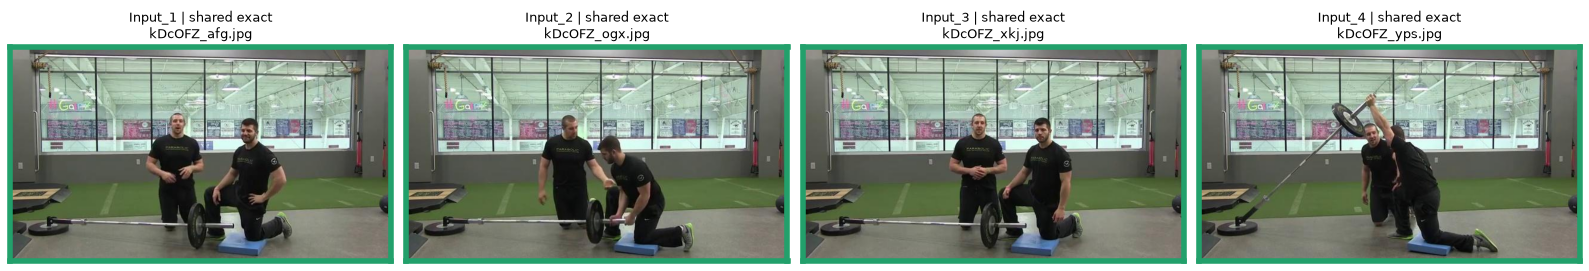


Id: H9sabf
Caption: The barbell is lowered to rest horizontally on the floor as both individuals kneel upright; then, it is lifted from an upright position and returned to lying horizontally while one person kneels for guidance.
Answer: [1, 3, 4, 2]
시간순 Input 번호: [1, 4, 2, 3]


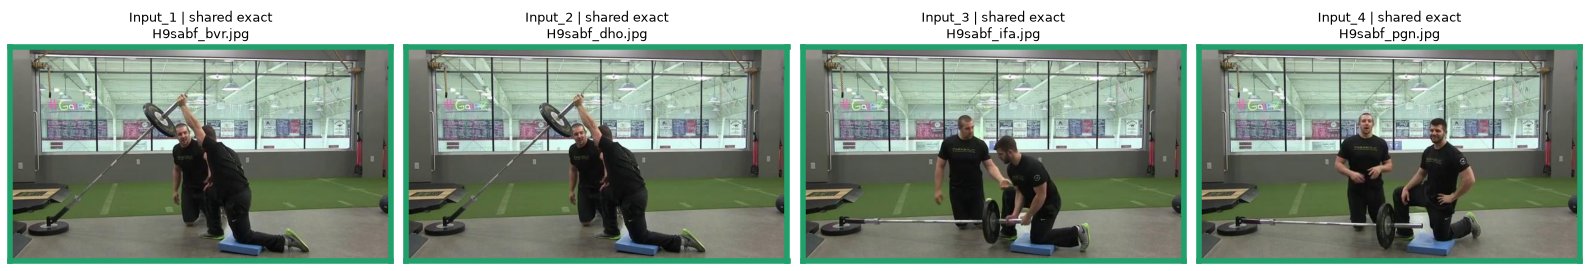


Id: gKkdPA
Caption: The barbell transitions from angled upright to horizontal on the floor as the athlete kneels, then is raised upright again before resting horizontally with both individuals kneeling beside it.
Answer: [1, 3, 4, 2]
시간순 Input 번호: [1, 4, 2, 3]


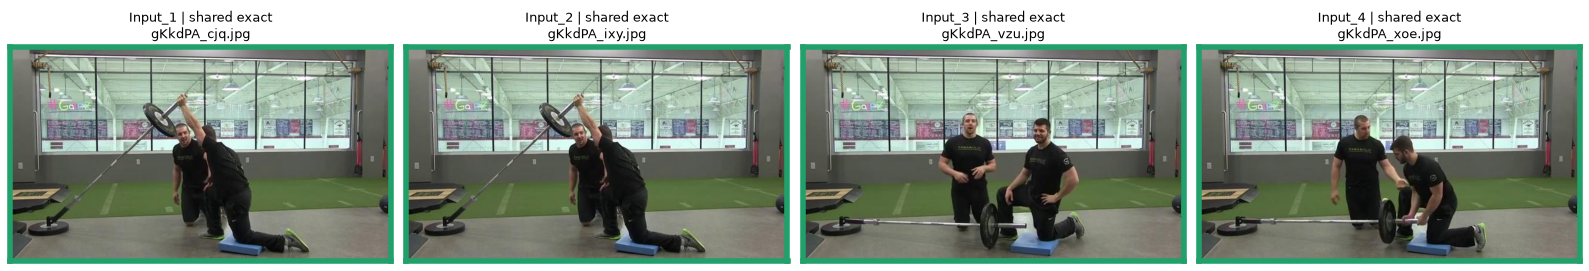


Id: ngtRKq
Caption: The trainee rises to stand beside the trainer, while the barbell remains stationary, then the athlete raises the barbell overhead and lowers it horizontally onto the floor as the trainer kneels for guidance.
Answer: [2, 4, 1, 3]
시간순 Input 번호: [3, 1, 4, 2]


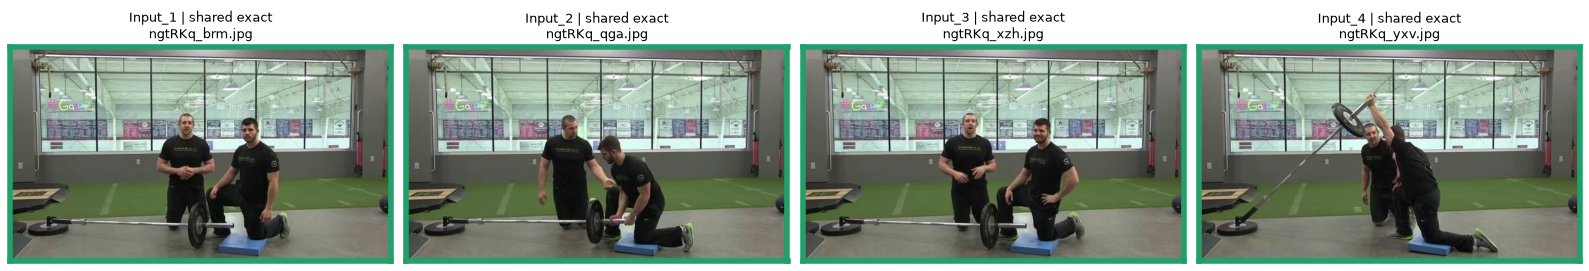


Id: HMTj1k
Caption: The man on the left kneels beside the barbell while the other holds it, then the barbell is raised overhead and returned to the floor as both individuals remain kneeling.
Answer: [3, 2, 4, 1]
시간순 Input 번호: [4, 2, 1, 3]


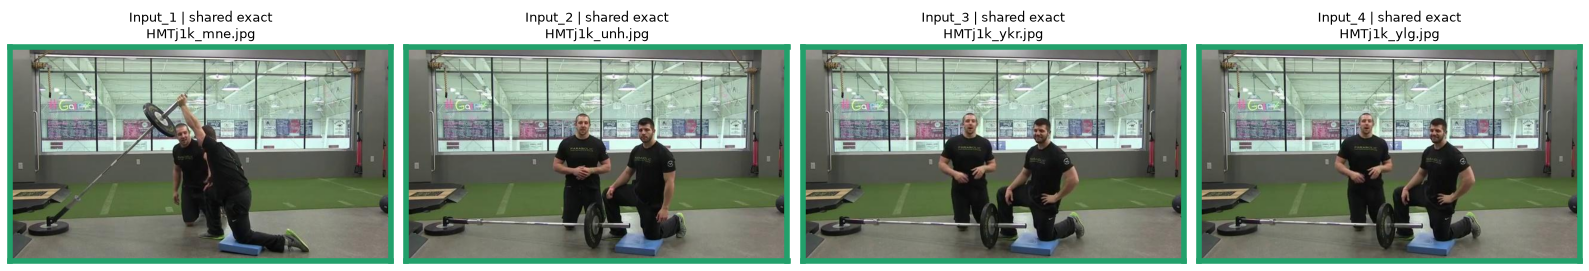

Group 3271 | split=validation | samples=4
공유된 exact image hash: 4개

Id: PJcT5r
Caption: The person squats with a resistance band around their waist as the instructor approaches from the right, then the athlete lifts the barbell higher while straightening their legs, with the camera remaining stationary.
Answer: [2, 4, 1, 3]
시간순 Input 번호: [3, 1, 4, 2]


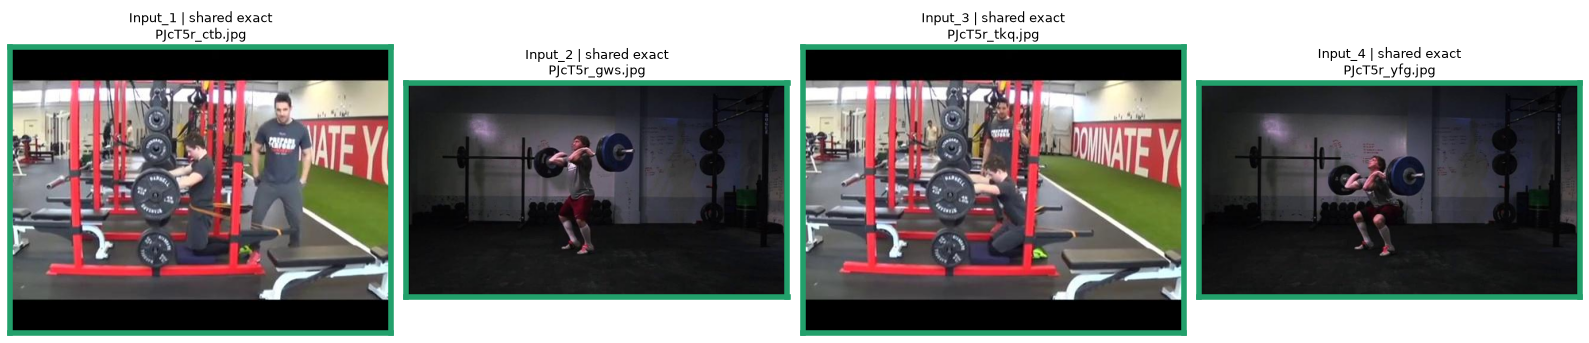


Id: WeyicF
Caption: The trainer approaches as a resistance band is added around the person squatting under the barbell, then the athlete lifts the barbell upward from a squat to a standing position, stabilizing it overhead.
Answer: [3, 2, 4, 1]
시간순 Input 번호: [4, 2, 1, 3]


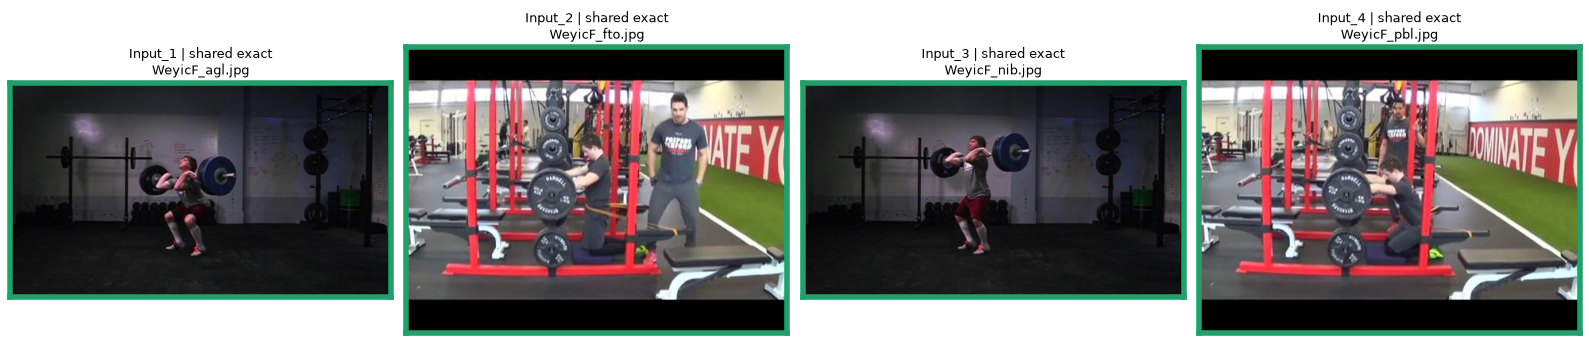


Id: LqoNRd
Caption: The athlete lifts the barbell upward, standing straighter as the camera tilts slightly, then a person squats under a barbell as an instructor approaches, adding a resistance band for support.
Answer: [1, 4, 2, 3]
시간순 Input 번호: [1, 3, 4, 2]


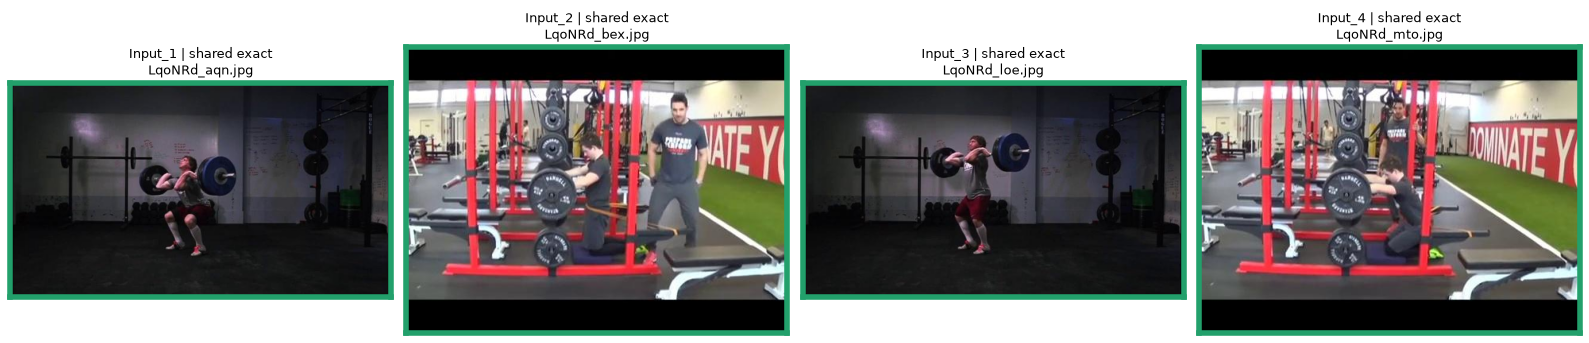


Id: jJ6mKi
Caption: The athlete lifts the barbell higher while standing more upright, then a resistance band appears as the trainer moves closer from left to right to assist the person squatting under the barbell.
Answer: [1, 3, 2, 4]
시간순 Input 번호: [1, 3, 2, 4]


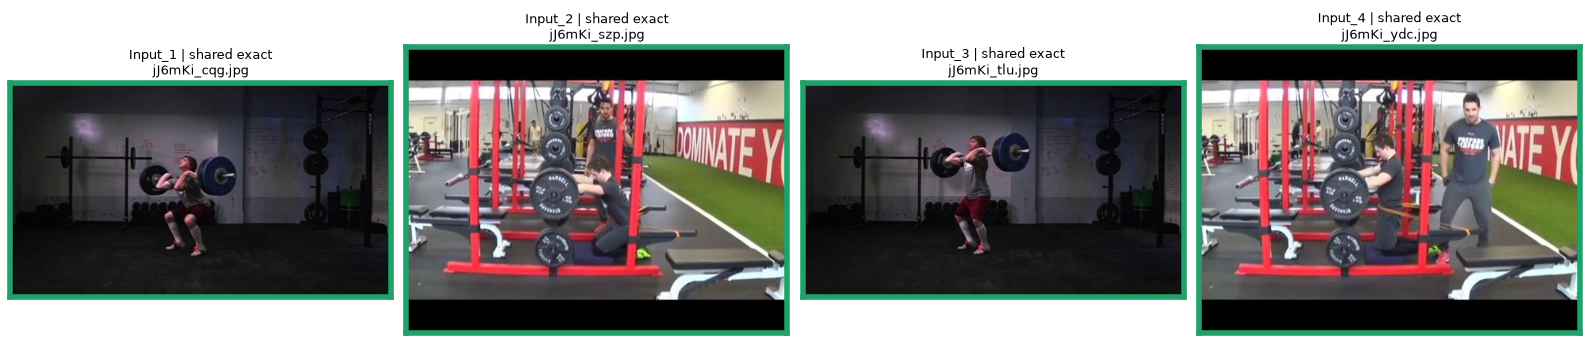

Group 1542 | split=train | samples=3
공유된 exact image hash: 4개

Id: AIzn2D
Caption: The climber ascends the rock face, moving upward and slightly right, then continues higher, gripping a hold as the camera zooms in slightly.
Answer: [4, 1, 2, 3]
시간순 Input 번호: [2, 3, 4, 1]


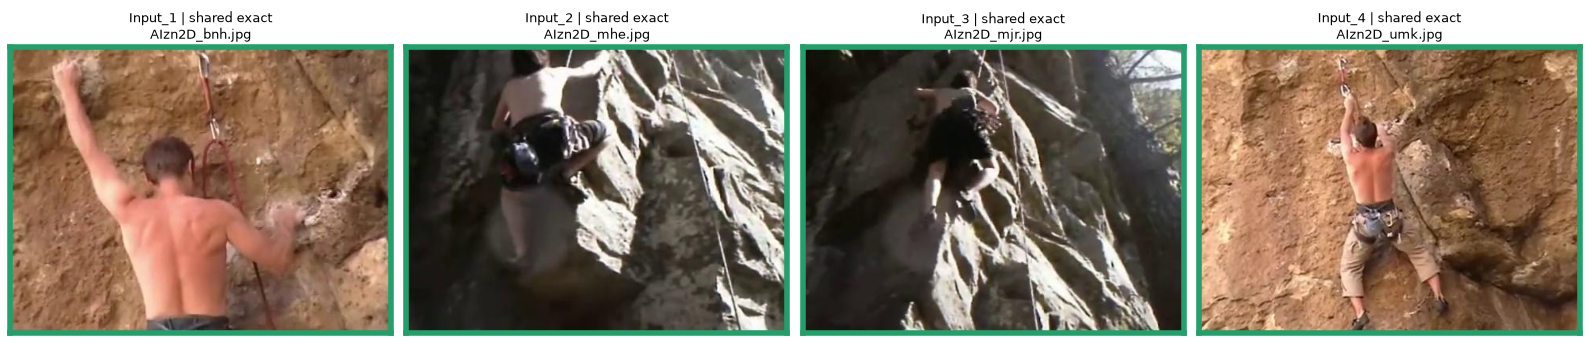


Id: MO9MY8
Caption: The climber ascends the rock face, raising his right hand to grip a higher hold as the camera zooms in, then continues moving upward, nearing a ledge with a secure stance.
Answer: [4, 3, 2, 1]
시간순 Input 번호: [4, 3, 2, 1]


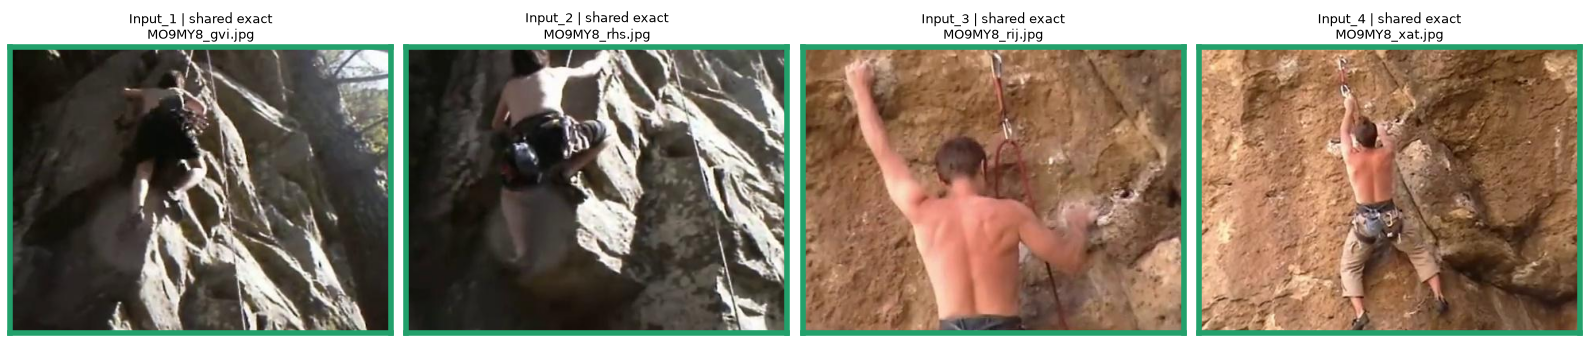


Id: vcd12L
Caption: The climber ascends the rock face, approaching a ledge as the camera tilts up slightly, then reaches higher, gripping holds with both hands, while the camera zooms in slightly.
Answer: [3, 2, 1, 4]
시간순 Input 번호: [3, 2, 1, 4]


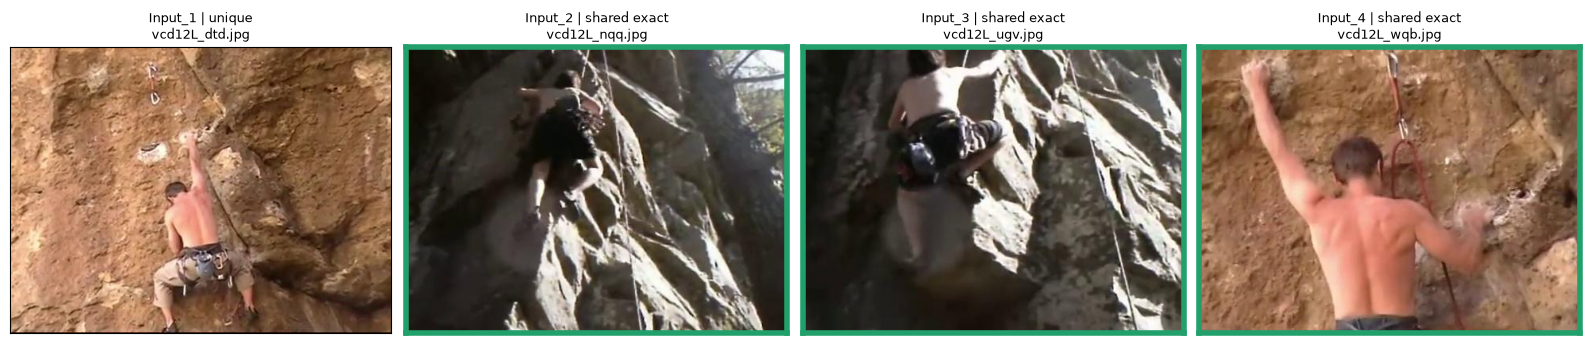

In [6]:
NUMBER_OF_GROUPS_TO_SHOW = 3

for component_id in group_overview.head(NUMBER_OF_GROUPS_TO_SHOW)['duplicate_component_id']:
    show_group(int(component_id))

## 6. 원하는 그룹 ID 직접 확인

위 표의 `duplicate_component_id` 중 하나를 입력하면 해당 그룹만 다시 볼 수 있습니다.

In [7]:
GROUP_ID = None  # 예: 2580

if GROUP_ID is None:
    print('확인할 duplicate_component_id를 GROUP_ID에 입력하세요.')
else:
    show_group(int(GROUP_ID))

확인할 duplicate_component_id를 GROUP_ID에 입력하세요.


## 검수할 때 볼 항목

- 초록색으로 표시된 이미지가 실제로 같은 장면인지
- 같은 그룹의 caption들이 같은 영상이나 매우 가까운 사건을 묘사하는지
- 검은 화면 같은 정보 없는 이미지만으로 묶인 그룹은 없는지
- 그룹의 모든 sample ID가 동일한 `split`에 들어갔는지

눈으로 보기에 잘못 묶인 그룹이 있더라도 이 Notebook에서 원본이나 CSV를 직접 고치지는 않습니다. 그룹 기준을 검토한 뒤 `scripts.make_split`으로 전체 분할을 다시 생성해야 재현성이 유지됩니다.